In [5]:
import pandas as pd
# Load the rtail dataset
df = pd.read_csv("SampleSuperstore.csv")
#display the first few rows of the dataset
print(df.head())
#check the data size
print(f"Dataset size: {df.shape}")
#check column names and data types
print(df.info())
#check for missing values
print(df.isnull().sum())

        Ship Mode    Segment        Country             City       State  \
0    Second Class   Consumer  United States        Henderson    Kentucky   
1    Second Class   Consumer  United States        Henderson    Kentucky   
2    Second Class  Corporate  United States      Los Angeles  California   
3  Standard Class   Consumer  United States  Fort Lauderdale     Florida   
4  Standard Class   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region         Category Sub-Category     Sales  Quantity  \
0        42420  South        Furniture    Bookcases  261.9600         2   
1        42420  South        Furniture       Chairs  731.9400         3   
2        90036   West  Office Supplies       Labels   14.6200         2   
3        33311  South        Furniture       Tables  957.5775         5   
4        33311  South  Office Supplies      Storage   22.3680         2   

   Discount    Profit  
0      0.00   41.9136  
1      0.00  219.5820  
2      0.00    6.871

In [6]:
#check for duplicate rows
print(f"Number of duplicate rows: {df.duplicated().sum()}")
#check numerical summary
print(df[['Sales', 'Quantity', 'Discount', 'Profit']].describe())
#check unique values in important categorical columns
print("categories:",df['Category'].unique())
print("regions:",df['Region'].unique())
#check for invalid values
print("sales <=0",(df['Sales'] <= 0).sum())
print("quantity <=0",(df['Quantity'] <= 0).sum())
#display the first few rows of the dataset
display(df.head())

Number of duplicate rows: 17
              Sales     Quantity     Discount       Profit
count   9994.000000  9994.000000  9994.000000  9994.000000
mean     229.858001     3.789574     0.156203    28.656896
std      623.245101     2.225110     0.206452   234.260108
min        0.444000     1.000000     0.000000 -6599.978000
25%       17.280000     2.000000     0.000000     1.728750
50%       54.490000     3.000000     0.200000     8.666500
75%      209.940000     5.000000     0.200000    29.364000
max    22638.480000    14.000000     0.800000  8399.976000
categories: <ArrowStringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str
regions: <ArrowStringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str
sales <=0 0
quantity <=0 0


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [7]:
# Show the duplicate records
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in exact duplicates:", len(duplicates))
display(duplicates.head(10))

Rows involved in exact duplicates: 34


,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
568,Standard Class,Corporate,United States,Seattle,Washington,98105,West,Office Supplies,Paper,19.440,3,0.0,9.3312
591,Standard Class,Consumer,United States,Salem,Oregon,97301,West,Office Supplies,Paper,10.368,2,0.2,3.6288
935,Standard Class,Home Office,United States,Philadelphia,Pennsylvania,19120,East,Office Supplies,Paper,15.552,3,0.2,5.4432
950,Standard Class,Home Office,United States,Philadelphia,Pennsylvania,19120,East,Office Supplies,Paper,15.552,3,0.2,5.4432
1186,Standard Class,Corporate,United States,Seattle,Washington,98103,West,Office Supplies,Paper,25.920,4,0.0,12.4416
1479,Standard Class,Consumer,United States,San Francisco,California,94122,West,Office Supplies,Paper,25.920,4,0.0,12.4416
2803,Standard Class,Consumer,United States,San Francisco,California,94122,West,Office Supplies,Paper,12.840,3,0.0,5.7780
2807,Second Class,Consumer,United States,Seattle,Washington,98115,West,Office Supplies,Paper,12.960,2,0.0,6.2208
2836,Standard Class,Consumer,United States,Los Angeles,California,90036,West,Office Supplies,Paper,19.440,3,0.0,9.3312
3127,Standard Class,Consumer,United States,New York City,New York,10011,East,Office Supplies,Paper,49.120,4,0.0,23.0864


In [8]:
# Create a cleaned copy of the dataset
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Original rows: 9994
Cleaned rows: 9977
Duplicates remaining: 0


In [9]:
# Step 6: Calculate key business metrics

total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
total_quantity = df_clean["Quantity"].sum()
average_sales = df_clean["Sales"].mean()

print("===== RETAIL SALES SUMMARY =====")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Sales per Row: ${average_sales:,.2f}")

===== RETAIL SALES SUMMARY =====
Total Sales: $2,296,195.59
Total Profit: $286,241.42
Total Quantity Sold: 37,820
Average Sales per Row: $230.15


In [10]:
# Step 7: Sales and profit by category

category_summary = (
    df_clean.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .round(2)
    .sort_values("Total_Sales", ascending=False)
)

display(category_summary)

,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Technology,836154.03,145454.95,6939
Furniture,741306.31,18421.81,8020
Office Supplies,718735.24,122364.66,22861


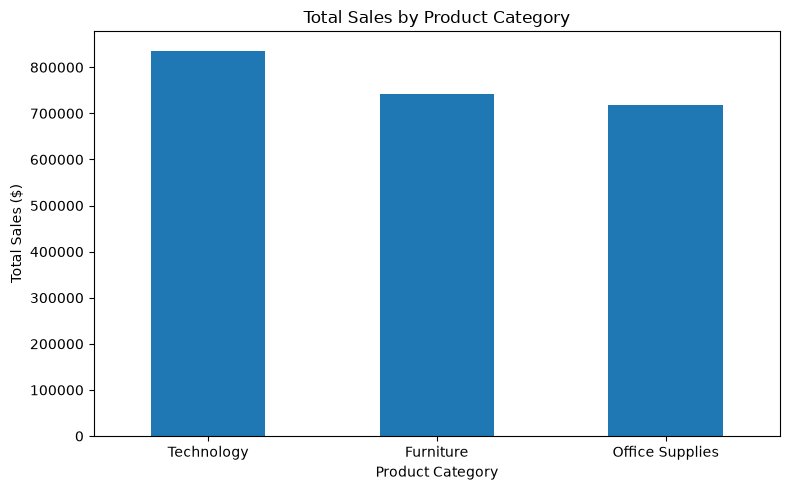

In [11]:
import matplotlib.pyplot as plt

category_summary["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Product Category"
)

plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# Step 9: Regional sales and profit analysis

region_summary = (
    df_clean.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .round(2)
    .sort_values("Total_Sales", ascending=False)
)

display(region_summary)

,Total_Sales,Total_Profit,Total_Quantity
Region,,,
West,725255.64,108329.81,12234
East,678435.20,91506.31,10609
Central,500782.85,39655.88,8768
South,391721.90,46749.43,6209


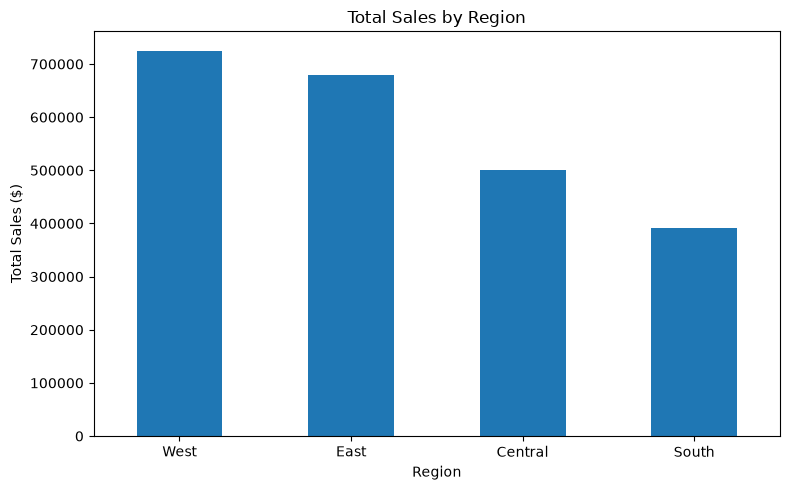

In [13]:
import matplotlib.pyplot as plt

region_summary["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Region"
)

plt.xlabel("Region")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
# Step 10: Sub-category performance analysis

subcategory_summary = (
    df_clean.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .round(2)
    .sort_values("Total_Profit", ascending=False)
)

display(subcategory_summary)

,Total_Sales,Total_Profit,Total_Quantity
Sub-Category,,,
Copiers,149528.03,55617.82,234
Phones,330007.05,44515.73,3289
Accessories,167380.32,41936.64,2976
Paper,78224.14,33944.24,5144
Binders,203409.17,30228.00,5971
Chairs,327777.76,26567.13,2351
Storage,223843.61,21278.83,3158
Appliances,107532.16,18138.01,1729
Furnishings,91683.02,13052.72,3560


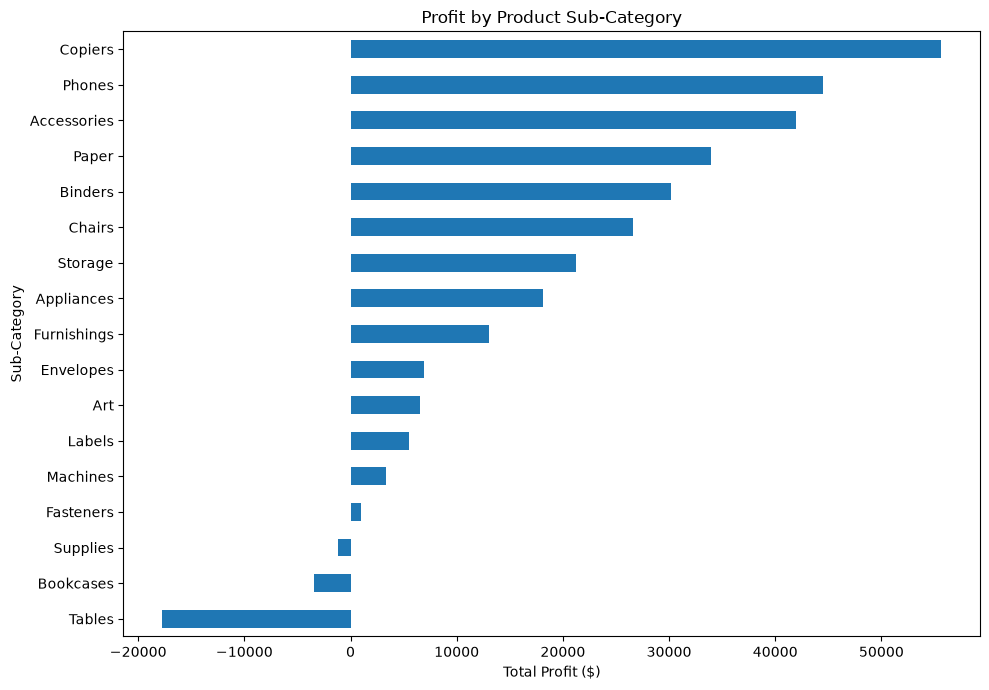

In [15]:
import matplotlib.pyplot as plt

subcategory_summary["Total_Profit"].sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Profit by Product Sub-Category"
)

plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

In [16]:
# Step 11: Export the cleaned dataset

df_clean.to_csv("retail_sales_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

Cleaned dataset exported successfully!
Rows: 9977
Columns: 13
